In [1]:
#importing libraries
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import PROCESSED_DIR
from src.preprocessing import build_preprocessor, numeric_cols
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

In [2]:
#loading train data
X_train = pd.read_parquet(PROCESSED_DIR / "X_train.parquet")
y_train = pd.read_parquet(PROCESSED_DIR / "y_train.parquet")["readmitted_30"]
groups_train = pd.read_parquet(PROCESSED_DIR / "groups_train.parquet")["patient_nbr"]
print(X_train.shape, y_train.shape)

(69613, 44) (69613,)


In [3]:
#encoding with our preprocessor
Xs_train = build_preprocessor().fit_transform(X_train)
print(Xs_train.shape)

(69613, 128)


In [4]:
#scaling all columns to variance 1
Xz_train = StandardScaler().set_output(transform="pandas").fit_transform(Xs_train)
print(Xz_train.var().round(3).unique())

[1.]


In [5]:
#centering and covariance functions
def center(X):
    mu = X.mean(axis=0)
    return X - mu, mu

def covariance_matrix(x_center):
    n = x_center.shape[0]
    return (x_center.T @ x_center) / (n - 1)

In [6]:
#pca fit function
def pca_fit(X, k):
    Xc, mu = center(X)
    C = covariance_matrix(Xc)
    vals, vecs = np.linalg.eigh(C)
    idx = np.argsort(vals)[::-1]
    vals = vals[idx]
    vecs = vecs[:, idx]
    return {
        "mean": mu,
        "components": vecs[:, :k],
        "explained_variance": vals[:k],
        "explained_variance_ratio": vals[:k] / np.sum(vals),
    }

In [7]:
#pca transform function
def pca_transform(X, model):
    return (X - model["mean"]) @ model["components"]

In [8]:
#building the covariance matrix
Xc_train, mu = center(Xz_train)
C = covariance_matrix(Xc_train)
print(C.shape)

(128, 128)


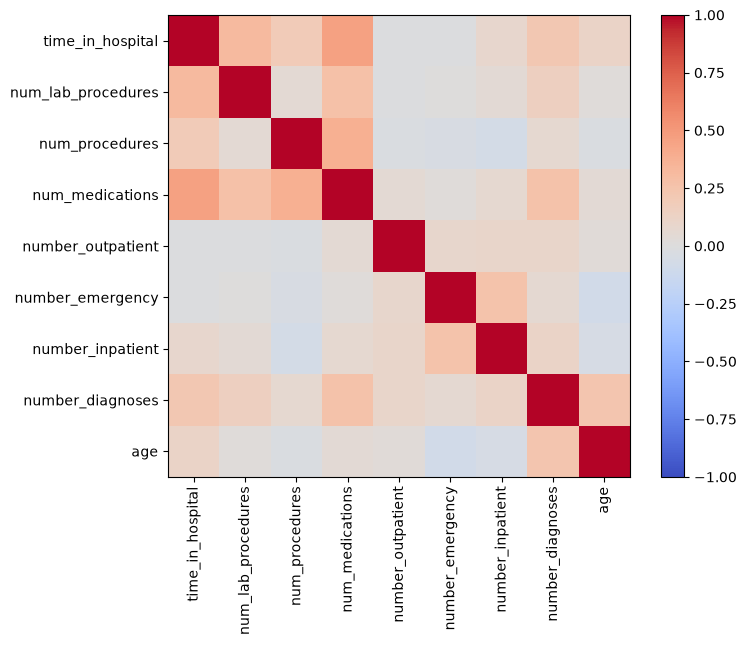

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,age
time_in_hospital,1.00,0.32,0.19,0.46,-0.01,-0.01,0.08,0.22,0.11
num_lab_procedures,0.32,1.00,0.05,0.27,-0.01,-0.00,0.04,0.15,0.02
num_procedures,0.19,0.05,1.00,0.38,-0.03,-0.04,-0.07,0.07,-0.03
num_medications,0.46,0.27,0.38,1.00,0.05,0.02,0.07,0.26,0.04
number_outpatient,-0.01,-0.01,-0.03,0.05,1.00,0.09,0.10,0.10,0.03
number_emergency,-0.01,-0.00,-0.04,0.02,0.09,1.00,0.25,0.06,-0.08
number_inpatient,0.08,0.04,-0.07,0.07,0.10,0.25,1.00,0.11,-0.05
number_diagnoses,0.22,0.15,0.07,0.26,0.10,0.06,0.11,1.00,0.24
age,0.11,0.02,-0.03,0.04,0.03,-0.08,-0.05,0.24,1.00


In [9]:
#covariance of the numeric features
num_part = C.loc[numeric_cols + ["age"], numeric_cols + ["age"]].round(2)
plt.figure(figsize=(8, 6))
plt.imshow(num_part, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(num_part)), num_part.columns, rotation=90)
plt.yticks(range(len(num_part)), num_part.columns)
plt.colorbar()
plt.show()
num_part

In [10]:
#finding strongest feature pairs
upper = C.where(np.triu(np.ones(C.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().rename("covariance").reset_index()
pairs["abs"] = pairs["covariance"].abs()
pairs.sort_values("abs", ascending=False).head(15).drop(columns="abs").round(3)

,level_0,level_1,covariance
1,race_AfricanAmerican,race_Caucasian,-0.830
7538,admission_source_id_1,admission_source_id_7,-0.732
6721,admission_type_id_1,admission_source_id_7,0.715
6715,admission_type_id_1,admission_source_id_1,-0.610
6818,admission_type_id_3,admission_source_id_1,0.597
1347,payer_code_MC,payer_code_Unknown,-0.550
8121,insulin,diabetesMed,0.523
7761,admission_source_id_17,max_glu_serum,0.521
6698,admission_type_id_1,admission_type_id_3,-0.508
8127,change,diabetesMed,0.505


In [11]:
#counting strong and weak pairs
print("pairs:", len(pairs))
print("pairs above 0.5:", (pairs["abs"] > 0.5).sum())
print("pairs below 0.1:", (pairs["abs"] < 0.1).sum())

pairs: 8128
pairs above 0.5: 12
pairs below 0.1: 7772


In [12]:
#fitting pca with all components
full = pca_fit(Xz_train, k=Xz_train.shape[1])
evr = full["explained_variance_ratio"]
cum = np.cumsum(evr)
print("first 10 components:", evr[:10].round(3))

first 10 components: [0.03  0.025 0.022 0.02  0.019 0.017 0.016 0.015 0.014 0.014]


In [13]:
#components needed for each variance level
for target in (0.80, 0.90, 0.95, 0.99):
    print(target, "variance needs", np.searchsorted(cum, target) + 1, "components")

0.8 variance needs 81 components
0.9 variance needs 96 components
0.95 variance needs 105 components
0.99 variance needs 115 components


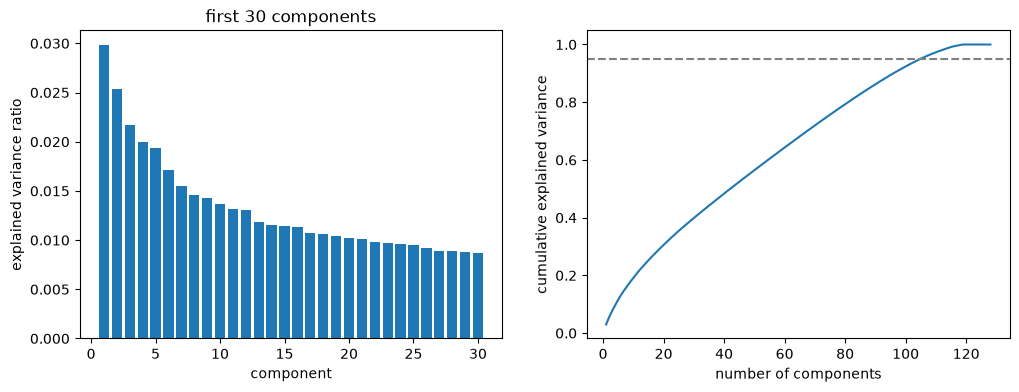

In [14]:
#scree and cumulative variance plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, 31), evr[:30])
ax[0].set_xlabel("component"); ax[0].set_ylabel("explained variance ratio"); ax[0].set_title("first 30 components")
ax[1].plot(range(1, len(cum) + 1), cum)
ax[1].axhline(0.95, ls="--", color="gray")
ax[1].set_xlabel("number of components"); ax[1].set_ylabel("cumulative explained variance")
plt.show()

In [15]:
#checking our numpy pca against sklearn
sk_pca = PCA().fit(Xz_train)
print(np.allclose(sk_pca.explained_variance_ratio_, evr))

True


In [16]:
#loadings of the first 3 components
loadings = pd.DataFrame(full["components"][:, :3], index=Xz_train.columns, columns=["PC1", "PC2", "PC3"])
for pc in loadings.columns:
    print(pc)
    print(loadings[pc].abs().sort_values(ascending=False).head(6).index.tolist())
    print()

PC1
['admission_source_id_7', 'admission_type_id_1', 'admission_source_id_1', 'admission_type_id_3', 'num_lab_procedures', 'num_procedures']

PC2
['number_diagnoses', 'num_medications', 'age', 'discharge_disposition_id_1', 'payer_code_MC', 'time_in_hospital']

PC3
['admission_source_id_17', 'max_glu_serum', 'admission_type_id_6', 'payer_code_Unknown', 'change', 'diabetesMed']



(69613, 2)


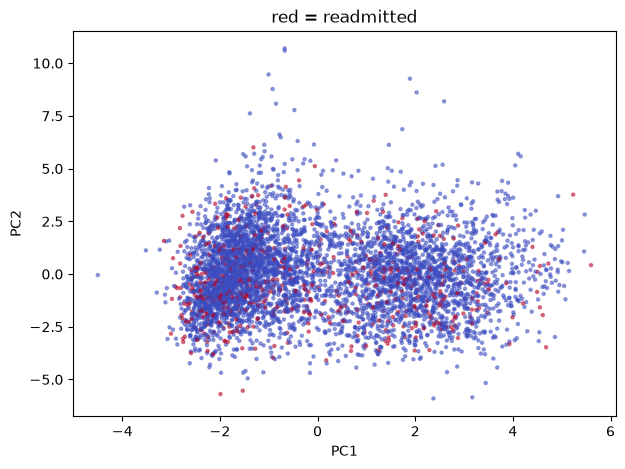

In [17]:
#projecting onto PC1 and PC2
model = pca_fit(Xz_train, k=2)
Z = pca_transform(Xz_train, model)
print(Z.shape)

sample = np.random.default_rng(42).choice(len(Z), 5000, replace=False)
plt.figure(figsize=(7, 5))
plt.scatter(Z.iloc[sample, 0], Z.iloc[sample, 1], c=y_train.iloc[sample], cmap="coolwarm", s=5, alpha=0.5)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("red = readmitted")
plt.show()

In [18]:
#building the pca pipeline
pca_model = Pipeline([
    ("pre", build_preprocessor()),
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=42)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

In [19]:
#cross validating pca + logistic regression
scores = cross_validate(pca_model, X_train, y_train, groups=groups_train, cv=cv, scoring="average_precision",
                        return_estimator=True, n_jobs=-1)

for fold, est in enumerate(scores["estimator"], start=1):
    print("fold", fold, "components:", est["pca"].n_components_, "PR-AUC:", round(scores["test_score"][fold - 1], 4))

fold 1 components: 103 PR-AUC: 0.2041
fold 2 components: 103 PR-AUC: 0.2098
fold 3 components: 103 PR-AUC: 0.205
fold 4 components: 103 PR-AUC: 0.2151
fold 5 components: 103 PR-AUC: 0.2224


In [20]:
#comparing with the baseline
baseline = json.load(open("../reports/baseline_results.json"))
pca_pr = scores["test_score"]
print("random model PR-AUC:", baseline["positive_rate"])
print("baseline PR-AUC:", baseline["cv_pr_auc"])
print("pca PR-AUC:", round(pca_pr.mean(), 4))
print("difference:", round(pca_pr.mean() - baseline["cv_pr_auc"], 4))

random model PR-AUC: 0.1137
baseline PR-AUC: 0.2129
pca PR-AUC: 0.2113
difference: -0.0016


In [21]:
#trying different numbers of components
rows = []
for k in [5, 10, 25, 50, 75, 100]:
    pca_model.set_params(pca__n_components=k)
    s = cross_validate(pca_model, X_train, y_train, groups=groups_train, cv=cv, scoring="average_precision", n_jobs=-1)
    rows.append({"components": k, "cv_pr_auc": s["test_score"].mean()})
    print(k, round(s["test_score"].mean(), 4))
k_results = pd.DataFrame(rows)

5 0.1382


10 0.1495


25 0.178


50 0.1947


75 0.2001


100 0.211


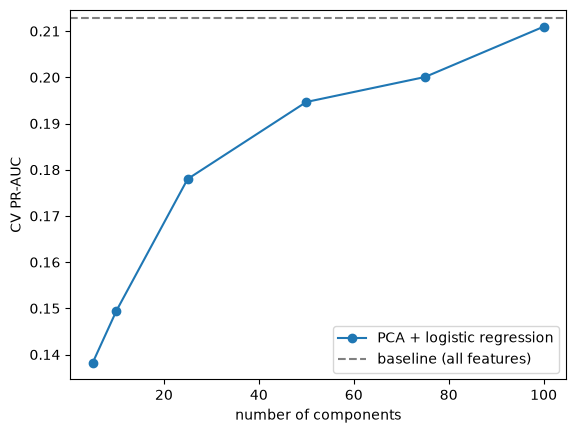

In [22]:
#plotting pr-auc by components
plt.plot(k_results["components"], k_results["cv_pr_auc"], marker="o", label="PCA + logistic regression")
plt.axhline(baseline["cv_pr_auc"], ls="--", color="gray", label="baseline (all features)")
plt.xlabel("number of components"); plt.ylabel("CV PR-AUC")
plt.legend()
plt.show()

In [23]:
#saving pca results
pca_results = {
    "model": "PCA (95% variance) + Logistic Regression (balanced)",
    "evaluation": "5-fold StratifiedGroupKFold on train, test not used",
    "n_components": int(np.searchsorted(cum, 0.95) + 1),
    "cv_pr_auc": round(float(pca_pr.mean()), 4),
    "cv_pr_auc_std": round(float(pca_pr.std(ddof=1)), 4),
    "pr_auc_by_components": k_results.round(4).to_dict("records"),
}
json.dump(pca_results, open("../reports/pca_results.json", "w"), indent=2)
pca_results

{'model': 'PCA (95% variance) + Logistic Regression (balanced)',
 'evaluation': '5-fold StratifiedGroupKFold on train, test not used',
 'n_components': 105,
 'cv_pr_auc': 0.2113,
 'cv_pr_auc_std': 0.0076,
 'pr_auc_by_components': [{'components': 5, 'cv_pr_auc': 0.1382},
  {'components': 10, 'cv_pr_auc': 0.1495},
  {'components': 25, 'cv_pr_auc': 0.178},
  {'components': 50, 'cv_pr_auc': 0.1947},
  {'components': 75, 'cv_pr_auc': 0.2001},
  {'components': 100, 'cv_pr_auc': 0.211}]}